# Wiqaya — Main analysis: wildfire susceptibility of the Bouhachem, Derdara and Jbel Sougna forests

**Arab Youth Space Hackathon 2026 · Theme: Climate & Disaster Resilience · Morocco**

This notebook reproduces the headline result of Wiqaya from the small inputs committed in `data/sample_input/`:

1. build a 250 m grid over the forest and compute terrain and population features;
2. turn 20 years of **NASA FIRMS** satellite fire detections into a per-cell fire history;
3. select a susceptibility model with **leave-one-year-out validation** (2017–2024);
4. **blind-test** it on the 2025 fires, never seen during training;
5. map the susceptibility on **1 August 2025**, before the two August 2025 fires → `results/example_output.png`;
6. optionally, compute the **weather danger index** of the 2025 fire days from Open-Meteo (needs internet).

**Runtime:** about 5 minutes on a standard laptop, no GPU. Steps 1–5 run offline; step 6 needs internet and is skipped
if the weather service does not answer. All paths are relative to the repository root and all random seeds are fixed.

In [1]:
import random
import sys
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", category=UserWarning)

# Repository root: works whether the notebook is started from the root or from notebooks/
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import wiqaya_model as wm

RESULTS = ROOT / "results"
RESULTS.mkdir(exist_ok=True)

random.seed(wm.SEED)
np.random.seed(wm.SEED)
pd.set_option("display.precision", 3)

ANALYSIS_DATE = "2025-08-01"   # fire history known on this date; the 2025 fires started on 12 and 21 August
print("Repository root:", ROOT.name)
print("Inputs:", sorted(p.name for p in wm.DATA.iterdir()))

Repository root: wiqayagit
Inputs: ['dem_30m.tif', 'firms_fire_detections.gpkg', 'forest_boundaries.gpkg', 'population_2017_100m.tif']


## 1. Inputs: forest boundaries and NASA FIRMS fire detections

All layers are in Merchich / Nord Maroc (EPSG:26191). FIRMS detections combine MODIS (2005–2017) and VIIRS S-NPP 375 m
(2017–2026), kept within 5 km of the forest.

In [2]:
forest = wm.load_forest()
firms = wm.load_firms(forest)
forest_union = forest.geometry.union_all()

print(f"Forest: {len(forest)} parts, {forest.area.sum() / 1e4:,.0f} ha")
print(f"FIRMS: {len(firms):,} detections from {firms.date.min().date()} to {firms.date.max().date()}")
inside = firms[firms.geometry.within(forest_union)]
print(f"       {len(inside):,} of them inside the forest")
inside.groupby(inside.date.dt.year).size().rename("detections inside the forest").to_frame().T

Forest: 6 parts, 25,866 ha
FIRMS: 1,176 detections from 2005-05-09 to 2026-06-05


       445 of them inside the forest


date,2005,2009,2011,2012,2013,2014,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
detections inside the forest,3,6,3,4,2,1,2,14,1,9,119,82,143,9,5,41,1


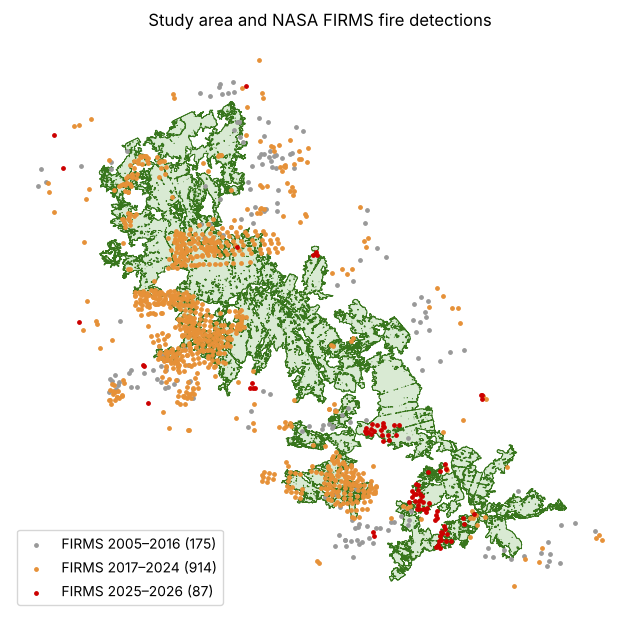

In [3]:
fig, ax = plt.subplots(figsize=(8, 8))
forest.plot(ax=ax, color="#d9ead3", edgecolor="#38761d", linewidth=0.6)
for (label, period), colour in zip({"2005–2016": (2005, 2016), "2017–2024": (2017, 2024), "2025–2026": (2025, 2026)}.items(),
                                    ["#999999", "#e69138", "#cc0000"]):
    pts = firms[firms.date.dt.year.between(*period)]
    pts.plot(ax=ax, color=colour, markersize=6, label=f"FIRMS {label} ({len(pts)})")
ax.set_title("Study area and NASA FIRMS fire detections")
ax.legend(loc="lower left")
ax.set_axis_off()
fig.savefig(RESULTS / "study_area_firms.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. 250 m grid, terrain and population features

Each cell is clipped to the forest. Elevation, slope and aspect come from the 30 m DEM (aspect is averaged circularly,
so 355° and 5° give north); population is the WorldPop 2017 count summed over the cell.

In [4]:
grid = wm.build_grid(forest)
cells = wm.terrain_and_population(grid)
print(f"{len(cells):,} cells of {wm.GRID} m")
cells[["elevation_m", "slope_pct", "aspect_deg", "population"]].describe().T

6,071 cells of 250 m


,count,mean,std,min,25%,50%,75%,max
elevation_m,6071.0,794.274,335.434,188.838,499.343,750.013,1068.940,1635.686
slope_pct,6071.0,23.791,12.162,1.576,14.683,20.055,30.662,84.536
aspect_deg,6071.0,174.468,107.280,0.020,71.731,185.980,266.970,359.986
population,6071.0,3.266,3.655,0.116,1.756,2.391,3.420,80.548


## 3. Fire history from FIRMS

A cell is marked as burned on a given day when a FIRMS detection falls within 375 m (half a VIIRS pixel). The model uses
the **years since the last fire**, always computed from fires strictly **before** the date studied, so there is no leakage.

In [5]:
history = wm.fire_history(firms, grid)
print(f"{len(history):,} (cell, date) burn records")
on_date = wm.add_fire_history(cells, history, ANALYSIS_DATE)
print(f"On {ANALYSIS_DATE}: {(on_date.years_since_last_fire < wm.YEARS_MAX).sum():,} cells have a known past fire, "
      f"{on_date.burned_last_5y.sum():,} burned in the last 5 years")

8,725 (cell, date) burn records
On 2025-08-01: 1,838 cells have a known past fire, 1,520 burned in the last 5 years


## 4. Model selection: leave-one-year-out validation (2017–2024)

One row per (cell, year): features with the fire history on 1 January, label = at least one FIRMS detection in the cell
that year. Each year is held out in turn, so the same fire is never both learned and evaluated. Predictions go through
the **fuel rule** (no fuel the year after a fire, risk halved for 1 to 5 years). Two candidates are compared.

In [6]:
panel = wm.yearly_panel(cells, firms, history, forest_union, wm.TRAINING_YEARS)
print(f"Panel: {len(panel):,} cell-years, {panel.fire.sum():,} with a fire")
validation = wm.leave_one_year_out(panel)
table = pd.DataFrame([{k: v for k, v in r.items() if k != "roc_auc_per_year"} | r["roc_auc_per_year"] for r in validation])
table.to_csv(RESULTS / "validation_leave_one_year_out.csv", index=False)
best = validation[0]["model"]
print("Selected model:", best)
table

Panel: 48,568 cell-years, 345 with a fire


Selected model: Logistic regression


,model,roc_auc_global,pr_lift,roc_auc_mean_per_year,2017,2018,2019,2020,2021,2022,2023,2024
0,Logistic regression,0.654,1.635,0.622,0.721,0.989,0.878,0.801,0.68,0.615,0.233,0.058
1,Random forest (regularised),0.604,1.313,0.562,0.639,0.778,0.788,0.705,0.60,0.637,0.229,0.119


## 5. Blind test on the 2025 fires

The selected model is retrained on 2017–2024 and scored on the FIRMS detections of 2025 (fire history on 1 August 2025).
`recall_top20` is the share of 2025 fire cells that fall inside the 20 % of the forest put in alert.

In [7]:
model = wm.CANDIDATE_MODELS[best]()
model.fit(panel[wm.FEATURES], panel.fire)
test = wm.blind_test(model, cells, firms, history, forest_union, ANALYSIS_DATE, "2025-01-01", "2025-12-31",
                     "FIRMS 2025 (trained on 2017-2024)")
pd.DataFrame([test]).to_csv(RESULTS / "blind_test_2025.csv", index=False)
pd.DataFrame([test])

,test,firms_points,fire_cells,roc_auc,pr_lift,recall_top20,precision_top20,precision_random
0,FIRMS 2025 (trained on 2017-2024),41,39,0.25,0.638,0.0,0.0,0.006


## 6. Headline result: susceptibility map on 1 August 2025

Susceptibility of every cell, 5 risk classes (KMeans) and the alert zones (riskiest 20 % of the forest), with the 2025
FIRMS detections that came afterwards. This figure is `results/example_output.png`, shown in the README.

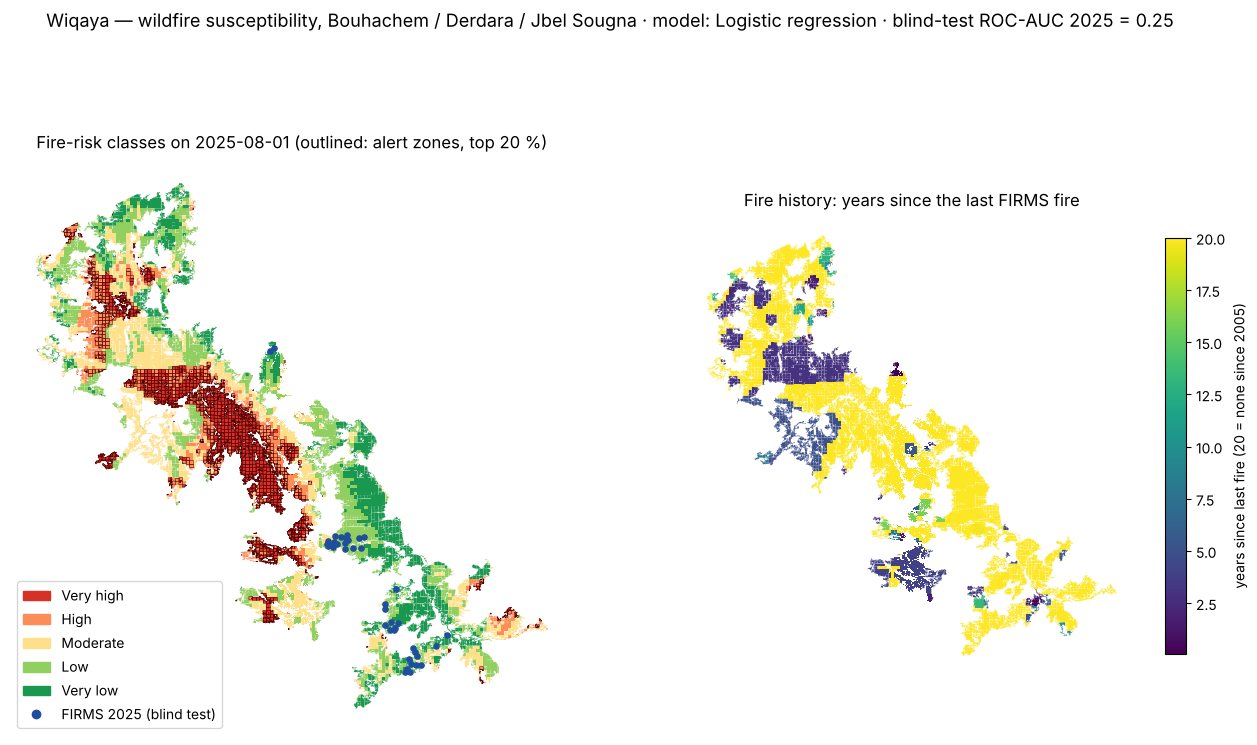

risk_class,1,2,3,4,5
cells per risk class,1111,1669,1626,910,755


In [8]:
risk, threshold = wm.susceptibility_map(model, cells, history, ANALYSIS_DATE)
risk.drop(columns="geometry").to_csv(RESULTS / f"risk_cells_{ANALYSIS_DATE}.csv", index=False)

colours = matplotlib.colors.ListedColormap(["#1a9850", "#91cf60", "#fee08b", "#fc8d59", "#d73027"])
fires_2025 = firms[(firms.date.dt.year == 2025) & firms.geometry.within(forest_union)]
fig, axes = plt.subplots(1, 2, figsize=(16, 9))
risk.plot(ax=axes[0], column="risk_class", cmap=colours, vmin=1, vmax=5, linewidth=0)
risk[risk.alert == 1].boundary.plot(ax=axes[0], color="#5a0000", linewidth=0.4)
fires_2025.plot(ax=axes[0], color="#1f4e9c", markersize=14, label=f"FIRMS 2025 ({len(fires_2025)} detections)")
axes[0].set_title(f"Fire-risk classes on {ANALYSIS_DATE} (outlined: alert zones, top 20 %)")
handles = [matplotlib.patches.Patch(color=colours(i), label=l)
           for i, l in enumerate(["Very low", "Low", "Moderate", "High", "Very high"])][::-1]
handles.append(matplotlib.lines.Line2D([], [], color="#1f4e9c", marker="o", linestyle="", label="FIRMS 2025 (blind test)"))
axes[0].legend(handles=handles, loc="lower left")
risk.plot(ax=axes[1], column="years_since_last_fire", cmap="viridis", legend=True, linewidth=0,
          legend_kwds={"label": "years since last fire (20 = none since 2005)", "shrink": 0.6})
axes[1].set_title("Fire history: years since the last FIRMS fire")
for ax in axes:
    ax.set_axis_off()
fig.suptitle(f"Wiqaya — wildfire susceptibility, Bouhachem / Derdara / Jbel Sougna · model: {best} · "
             f"blind-test ROC-AUC 2025 = {test['roc_auc']:.2f}", fontsize=13)
fig.savefig(RESULTS / "example_output.png", dpi=150, bbox_inches="tight")
plt.show()
risk.risk_class.value_counts().sort_index().rename("cells per risk class").to_frame().T

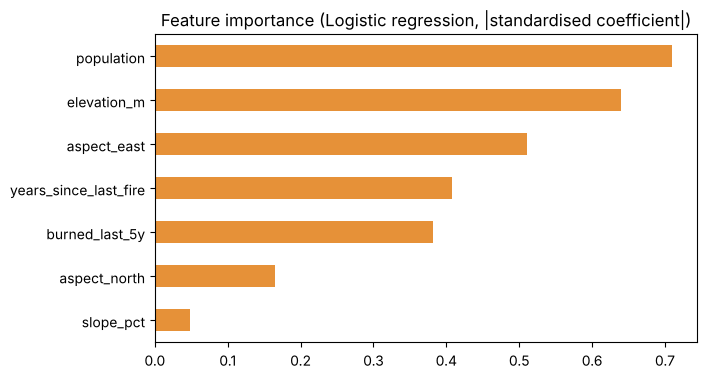

In [9]:
importance = pd.Series(wm.feature_importance(model)).sort_values()
ax = importance.plot.barh(figsize=(7, 4), color="#e69138", title=f"Feature importance ({best}, |standardised coefficient|)")
ax.figure.savefig(RESULTS / "feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Weather danger index of the 2025 fire days (needs internet)

The daily weather (max temperature, max vapour-pressure deficit, max wind, min humidity) at the forest centre is ranked
against every June–September day of 2017–2024 from the Open-Meteo ERA5-based archive. The index is the mean of the four
ranks: low < 0.25 ≤ moderate < 0.50 ≤ high < 0.75 ≤ very high. If the service does not answer, this step is skipped.

In [10]:
import requests

FIRE_DAYS = ["2025-08-12", "2025-08-21"]   # Derdara and Bouhachem-near-Derdara fires
lat, lon = wm.forest_centre_wgs84(forest)
try:
    r = requests.get("https://archive-api.open-meteo.com/v1/archive", timeout=180, params={
        "latitude": lat, "longitude": lon, "start_date": "2017-06-01", "end_date": "2025-09-30",
        "hourly": "temperature_2m,relative_humidity_2m,wind_speed_10m", "timezone": wm.TIMEZONE})
    r.raise_for_status()
    daily = wm.daily_weather(r.json()["hourly"])
    climatology = daily[daily.date.dt.month.isin(wm.SUMMER_MONTHS) & (daily.date.dt.year <= 2024)]
    rows = []
    for day in FIRE_DAYS:
        weather = daily[daily.date == pd.Timestamp(day)].iloc[0][list(wm.DANGER_VARS)].to_dict()
        rows.append({"date": day, **{k: round(v, 2) for k, v in weather.items()},
                     **{k: v for k, v in wm.danger_index(weather, climatology).items() if k != "parts"}})
    danger = pd.DataFrame(rows)
    danger.to_csv(RESULTS / "weather_danger_2025_fire_days.csv", index=False)
    display(danger)
except requests.RequestException as e:
    print("Open-Meteo did not answer, step skipped:", e)

Open-Meteo did not answer, step skipped: 429 Client Error: Too Many Requests for url: https://archive-api.open-meteo.com/v1/archive?latitude=35.22793745332732&longitude=-5.434392896243646&start_date=2017-06-01&end_date=2025-09-30&hourly=temperature_2m%2Crelative_humidity_2m%2Cwind_speed_10m&timezone=Africa%2FCasablanca


## Summary

In [11]:
v = validation[0]
print(f"Cells: {len(cells):,} of 250 m  |  FIRMS detections: {len(firms):,} ({firms.date.min().year}-{firms.date.max().year})")
print(f"Selected model: {best}")
print(f"Leave-one-year-out 2017-2024: mean ROC-AUC per year = {v['roc_auc_mean_per_year']:.2f}, "
      f"global ROC-AUC = {v['roc_auc_global']:.2f}, PR lift = {v['pr_lift']:.2f}")
print(f"Blind test 2025: ROC-AUC = {test['roc_auc']:.2f}, recall in the top-20 % alert zones = {test['recall_top20']:.2f}")
print("Outputs:", sorted(p.name for p in RESULTS.iterdir()))

Cells: 6,071 of 250 m  |  FIRMS detections: 1,176 (2005-2026)
Selected model: Logistic regression
Leave-one-year-out 2017-2024: mean ROC-AUC per year = 0.62, global ROC-AUC = 0.65, PR lift = 1.64
Blind test 2025: ROC-AUC = 0.25, recall in the top-20 % alert zones = 0.00
Outputs: ['blind_test_2025.csv', 'example_output.png', 'feature_importance.png', 'risk_cells_2025-08-01.csv', 'study_area_firms.png', 'validation_leave_one_year_out.csv']
